In [10]:

from pathlib import Path
import torch
import pandas as pd

PROJECT = Path("/kaggle/working/ubiris_v2_project")
PRE_DIR = PROJECT / "notebook02_preprocessing"
BASELINE_DIR = PROJECT / "notebook04_baseline_recognition"
OUT_DIR = PROJECT / "notebook06_diffusion_training"

IMG_DIR = PRE_DIR / "images_224"
TRAIN_CSV = BASELINE_DIR / "UBIRIS_V2_train_split.csv"

OUT_DIR.mkdir(parents=True, exist_ok=True)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

assert IMG_DIR.is_dir(), f"Preprocessed images missing: {IMG_DIR}"
assert TRAIN_CSV.is_file(), f"Training split missing: {TRAIN_CSV}"

train_df = pd.read_csv(TRAIN_CSV)
print("\nTraining split rows:", len(train_df))
print("Preprocessed image directory:", IMG_DIR)
print("Training split:", TRAIN_CSV)

assert len(train_df) > 0, "Training split is empty."

# Verify a sample image can be found.
sample_name = Path(str(train_df.iloc[0]["filename"])).stem + ".png"
sample_path = IMG_DIR / sample_name
assert sample_path.is_file(), f"Sample image missing: {sample_path}"

print("Sample image verified:", sample_path.name)
print("\nSetup checks passed.")


PyTorch: 2.11.0+cu128
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

Training split rows: 4243
Preprocessed image directory: /kaggle/working/ubiris_v2_project/notebook02_preprocessing/images_224
Training split: /kaggle/working/ubiris_v2_project/notebook04_baseline_recognition/UBIRIS_V2_train_split.csv
Sample image verified: C157_S1_I3.png

Setup checks passed.


In [11]:

from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

PROJECT = Path("/kaggle/working/ubiris_v2_project")
PRE_DIR = PROJECT / "notebook02_preprocessing"
BASELINE_DIR = PROJECT / "notebook04_baseline_recognition"
OUT_DIR = PROJECT / "notebook06_diffusion_training"
IMG_DIR = PRE_DIR / "images_224"

train_df = pd.read_csv(
    BASELINE_DIR / "UBIRIS_V2_train_split.csv"
)

class UBIRISOcularDataset(Dataset):
    def __init__(self, dataframe, image_dir):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.transform = transforms.Compose([
            transforms.Grayscale(num_output_channels=1),
            transforms.ToTensor(),
            transforms.Normalize((0.5,), (0.5,))
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        filename = Path(str(self.df.iloc[idx]["filename"])).stem + ".png"
        image_path = self.image_dir / filename

        with Image.open(image_path) as image:
            image = image.convert("L")
            image = self.transform(image)

        return image

dataset = UBIRISOcularDataset(train_df, IMG_DIR)

# Start conservatively; tune after checking throughput and memory.
BATCH_SIZE = 16
NUM_WORKERS = 2

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    drop_last=True
)

batch = next(iter(loader))
print("Dataset size:", len(dataset))
print("Batch shape:", tuple(batch.shape))
print("Batch dtype:", batch.dtype)
print("Pixel range:", (batch.min().item(), batch.max().item()))

assert batch.shape == (BATCH_SIZE, 1, 224, 224)
assert torch.isfinite(batch).all()
assert batch.min().item() >= -1.01 and batch.max().item() <= 1.01

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)
        print(
            f"GPU {i}: {props.name}, "
            f"memory {props.total_memory / 1024**3:.2f} GiB"
        )

print("\nData pipeline checks passed.")


Dataset size: 4243
Batch shape: (16, 1, 224, 224)
Batch dtype: torch.float32
Pixel range: (-1.0, 1.0)
GPU 0: Tesla T4, memory 14.56 GiB
GPU 1: Tesla T4, memory 14.56 GiB

Data pipeline checks passed.


In [12]:

import math
import torch
import torch.nn as nn
import torch.nn.functional as F

# --------------------------------------------------
# 1. Time-step embedding
# --------------------------------------------------
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, timesteps):
        half = self.dim // 2
        scale = math.log(10000) / max(half - 1, 1)
        frequencies = torch.exp(
            -scale * torch.arange(
                half, device=timesteps.device, dtype=torch.float32
            )
        )
        angles = timesteps.float()[:, None] * frequencies[None, :]
        embedding = torch.cat(
            [torch.sin(angles), torch.cos(angles)], dim=1
        )
        if embedding.shape[1] < self.dim:
            embedding = F.pad(embedding, (0, self.dim - embedding.shape[1]))
        return embedding


# --------------------------------------------------
# 2. Time-conditioned residual block
# --------------------------------------------------
class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_proj = nn.Linear(time_dim, out_channels)
        self.norm2 = nn.GroupNorm(8, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = (
            nn.Identity() if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, 1)
        )

    def forward(self, x, time_embedding):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(F.silu(time_embedding))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


# --------------------------------------------------
# 3. Compact U-Net
# --------------------------------------------------
class OcularUNet(nn.Module):
    def __init__(self, base_channels=32, time_dim=128):
        super().__init__()
        c1, c2, c3 = base_channels, base_channels * 2, base_channels * 4

        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim * 2),
            nn.SiLU(),
            nn.Linear(time_dim * 2, time_dim)
        )

        self.input_conv = nn.Conv2d(1, c1, 3, padding=1)

        self.down1 = ResBlock(c1, c1, time_dim)
        self.downsample1 = nn.Conv2d(c1, c2, 4, stride=2, padding=1)

        self.down2 = ResBlock(c2, c2, time_dim)
        self.downsample2 = nn.Conv2d(c2, c3, 4, stride=2, padding=1)

        self.middle1 = ResBlock(c3, c3, time_dim)
        self.middle2 = ResBlock(c3, c3, time_dim)

        self.upsample2 = nn.ConvTranspose2d(c3, c2, 4, stride=2, padding=1)
        self.up2 = ResBlock(c2 * 2, c2, time_dim)

        self.upsample1 = nn.ConvTranspose2d(c2, c1, 4, stride=2, padding=1)
        self.up1 = ResBlock(c1 * 2, c1, time_dim)

        self.output_norm = nn.GroupNorm(8, c1)
        self.output_conv = nn.Conv2d(c1, 1, 3, padding=1)

    def forward(self, x, timesteps):
        t = self.time_mlp(timesteps)

        x1 = self.input_conv(x)
        d1 = self.down1(x1, t)
        x2 = self.downsample1(d1)

        d2 = self.down2(x2, t)
        x3 = self.downsample2(d2)

        h = self.middle1(x3, t)
        h = self.middle2(h, t)

        u2 = self.upsample2(h)
        u2 = self.up2(torch.cat([u2, d2], dim=1), t)

        u1 = self.upsample1(u2)
        u1 = self.up1(torch.cat([u1, d1], dim=1), t)

        return self.output_conv(F.silu(self.output_norm(u1)))


# --------------------------------------------------
# 4. Initialize and check shape
# --------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = OcularUNet(base_channels=32).to(device)

if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

test_images = batch.to(device)
test_timesteps = torch.randint(
    0, 1000, (test_images.shape[0],), device=device
)

with torch.no_grad():
    predicted_noise = model(test_images, test_timesteps)

print("Device:", device)
print("Model parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Input shape:", tuple(test_images.shape))
print("Predicted noise shape:", tuple(predicted_noise.shape))

assert predicted_noise.shape == test_images.shape
assert torch.isfinite(predicted_noise).all()

print("U-Net forward-pass check passed.")


Device: cuda
Model parameters: 1,285,793
Input shape: (16, 1, 224, 224)
Predicted noise shape: (16, 1, 224, 224)
U-Net forward-pass check passed.


In [13]:

import torch
import torch.nn.functional as F

# --------------------------------------------------
# DDPM noise schedule
# --------------------------------------------------
TIMESTEPS = 1000
BETA_START = 1e-4
BETA_END = 0.02

betas = torch.linspace(
    BETA_START, BETA_END, TIMESTEPS, dtype=torch.float32
).to(device)

alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)

def extract(schedule, timesteps, x_shape):
    """Select per-image schedule values and broadcast across image dimensions."""
    values = schedule.gather(0, timesteps)
    return values.reshape(timesteps.shape[0], *([1] * (len(x_shape) - 1)))

def q_sample(x_start, timesteps, noise=None):
    """Sample a noisy image at arbitrary diffusion timesteps."""
    if noise is None:
        noise = torch.randn_like(x_start)

    signal = extract(sqrt_alphas_cumprod, timesteps, x_start.shape)
    noise_scale = extract(
        sqrt_one_minus_alphas_cumprod, timesteps, x_start.shape
    )
    return signal * x_start + noise_scale * noise, noise

# --------------------------------------------------
# Test at early, middle, and late timesteps
# --------------------------------------------------
x_start = batch[:4].to(device)
test_t = torch.tensor([0, 100, 500, 999], device=device)

torch.manual_seed(42)
x_noisy, true_noise = q_sample(x_start, test_t)

print("Timesteps:", test_t.tolist())
print("Original shape:", tuple(x_start.shape))
print("Noisy shape:", tuple(x_noisy.shape))
print("True noise shape:", tuple(true_noise.shape))
print("Beta range:", (betas[0].item(), betas[-1].item()))
print("Cumulative alpha:", alphas_cumprod[test_t].tolist())
print("Noisy image range:", (x_noisy.min().item(), x_noisy.max().item()))

assert x_noisy.shape == x_start.shape
assert true_noise.shape == x_start.shape
assert torch.isfinite(x_noisy).all()
assert torch.isfinite(true_noise).all()
assert torch.all(alphas_cumprod[1:] < alphas_cumprod[:-1])

print("\nDDPM noise-schedule checks passed.")


Timesteps: [0, 100, 500, 999]
Original shape: (4, 1, 224, 224)
Noisy shape: (4, 1, 224, 224)
True noise shape: (4, 1, 224, 224)
Beta range: (9.999999747378752e-05, 0.019999999552965164)
Cumulative alpha: [0.9998999834060669, 0.8951412439346313, 0.07779667526483536, 4.035829260828905e-05]
Noisy image range: (-4.561474800109863, 4.190710067749023)

DDPM noise-schedule checks passed.


In [14]:

import time
import torch
import torch.nn as nn
import torch.nn.functional as F

# --------------------------------------------------
# One-step training smoke test
# --------------------------------------------------
model.train()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

# Start with a small batch for a safe memory test.
test_batch = next(iter(loader))[:8].to(device, non_blocking=True)
batch_size = test_batch.shape[0]

timesteps = torch.randint(
    0, TIMESTEPS, (batch_size,), device=device
)
noisy_images, true_noise = q_sample(test_batch, timesteps)

optimizer.zero_grad(set_to_none=True)
start = time.time()

# Use FP16 autocast on CUDA; GradScaler protects small gradients.
with torch.autocast(
    device_type="cuda",
    dtype=torch.float16,
    enabled=(device.type == "cuda")
):
    predicted_noise = model(noisy_images, timesteps)
    loss = F.mse_loss(predicted_noise.float(), true_noise.float())

assert torch.isfinite(loss), f"Non-finite loss: {loss.item()}"

if device.type == "cuda":
    scaler = torch.amp.GradScaler("cuda")
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(), max_norm=1.0
    )
    assert torch.isfinite(grad_norm), "Non-finite gradient norm."
    scaler.step(optimizer)
    scaler.update()
else:
    loss.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(), max_norm=1.0
    )
    assert torch.isfinite(grad_norm), "Non-finite gradient norm."
    optimizer.step()

if device.type == "cuda":
    torch.cuda.synchronize()

print(f"Batch size: {batch_size}")
print(f"Training loss: {loss.item():.6f}")
print(f"Gradient norm: {float(grad_norm):.6f}")
print(f"Step time: {time.time() - start:.2f} seconds")

if device.type == "cuda":
    for i in range(torch.cuda.device_count()):
        allocated = torch.cuda.memory_allocated(i) / 1024**3
        reserved = torch.cuda.memory_reserved(i) / 1024**3
        print(
            f"GPU {i} memory — allocated: {allocated:.2f} GiB, "
            f"reserved: {reserved:.2f} GiB"
        )

print("Single training-step check passed.")


Batch size: 8
Training loss: 1.002659
Gradient norm: 3.885533
Step time: 0.58 seconds
GPU 0 memory — allocated: 0.19 GiB, reserved: 1.08 GiB
GPU 1 memory — allocated: 0.02 GiB, reserved: 0.87 GiB
Single training-step check passed.


In [15]:

import csv
import time
import torch
import torch.nn.functional as F
from pathlib import Path
from tqdm.auto import tqdm

OUT_DIR = Path("/kaggle/working/ubiris_v2_project/notebook06_diffusion_training")
OUT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 2
LEARNING_RATE = 1e-4
CHECKPOINT_PATH = OUT_DIR / "UBIRIS_V2_ddpm_checkpoint.pth"
HISTORY_PATH = OUT_DIR / "UBIRIS_V2_ddpm_training_history.csv"

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

# Recreate scaler for the full training loop.
scaler = torch.amp.GradScaler(
    "cuda", enabled=(device.type == "cuda")
)

history = []
best_loss = float("inf")
start_training = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    batches_seen = 0
    epoch_start = time.time()

    progress = tqdm(loader, desc=f"Epoch {epoch}/{EPOCHS}")

    for images in progress:
        images = images.to(device, non_blocking=True)
        batch_size = images.shape[0]

        timesteps = torch.randint(
            0, TIMESTEPS, (batch_size,), device=device
        )
        noisy_images, true_noise = q_sample(images, timesteps)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            predicted_noise = model(noisy_images, timesteps)
            loss = F.mse_loss(
                predicted_noise.float(), true_noise.float()
            )

        if not torch.isfinite(loss):
            print("Non-finite loss encountered; stopping training.")
            break

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        if not torch.isfinite(grad_norm):
            print("Non-finite gradient encountered; stopping training.")
            break

        scaler.step(optimizer)
        scaler.update()

        epoch_loss += loss.item()
        batches_seen += 1

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            avg=f"{epoch_loss / batches_seen:.4f}"
        )

    if batches_seen == 0:
        raise RuntimeError(
            "No successful training batches. Check the preceding errors."
        )

    mean_loss = epoch_loss / batches_seen
    epoch_seconds = time.time() - epoch_start

    record = {
        "epoch": epoch,
        "mean_training_loss": mean_loss,
        "batches": batches_seen,
        "epoch_seconds": epoch_seconds,
        "learning_rate": LEARNING_RATE
    }
    history.append(record)

    with open(HISTORY_PATH, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=history[0].keys())
        writer.writeheader()
        writer.writerows(history)

    torch.save({
        "epoch": epoch,
        "model_state_dict": (
            model.module.state_dict()
            if isinstance(model, torch.nn.DataParallel)
            else model.state_dict()
        ),
        "optimizer_state_dict": optimizer.state_dict(),
        "mean_training_loss": mean_loss,
        "timesteps": TIMESTEPS,
        "model_base_channels": 32
    }, CHECKPOINT_PATH)

    if device.type == "cuda":
        torch.cuda.synchronize()
        gpu_memory = [
            round(torch.cuda.memory_allocated(i) / 1024**3, 3)
            for i in range(torch.cuda.device_count())
        ]
    else:
        gpu_memory = []

    print(
        f"\nEpoch {epoch}: loss={mean_loss:.6f}, "
        f"duration={epoch_seconds / 60:.2f} min, "
        f"GPU allocated memory (GiB)={gpu_memory}"
    )

    if mean_loss < best_loss:
        best_loss = mean_loss

print("\nPILOT TRAINING COMPLETE")
print(f"Total duration: {(time.time() - start_training) / 60:.2f} min")
print(f"Best training loss: {best_loss:.6f}")
print(f"Checkpoint: {CHECKPOINT_PATH}")
print(f"History: {HISTORY_PATH}")


Epoch 1/2:   0%|          | 0/265 [00:00<?, ?it/s]


Epoch 1: loss=0.071654, duration=0.59 min, GPU allocated memory (GiB)=[0.201, 0.018]


Epoch 2/2:   0%|          | 0/265 [00:00<?, ?it/s]


Epoch 2: loss=0.023885, duration=0.58 min, GPU allocated memory (GiB)=[0.202, 0.018]

PILOT TRAINING COMPLETE
Total duration: 1.17 min
Best training loss: 0.023885
Checkpoint: /kaggle/working/ubiris_v2_project/notebook06_diffusion_training/UBIRIS_V2_ddpm_checkpoint.pth
History: /kaggle/working/ubiris_v2_project/notebook06_diffusion_training/UBIRIS_V2_ddpm_training_history.csv


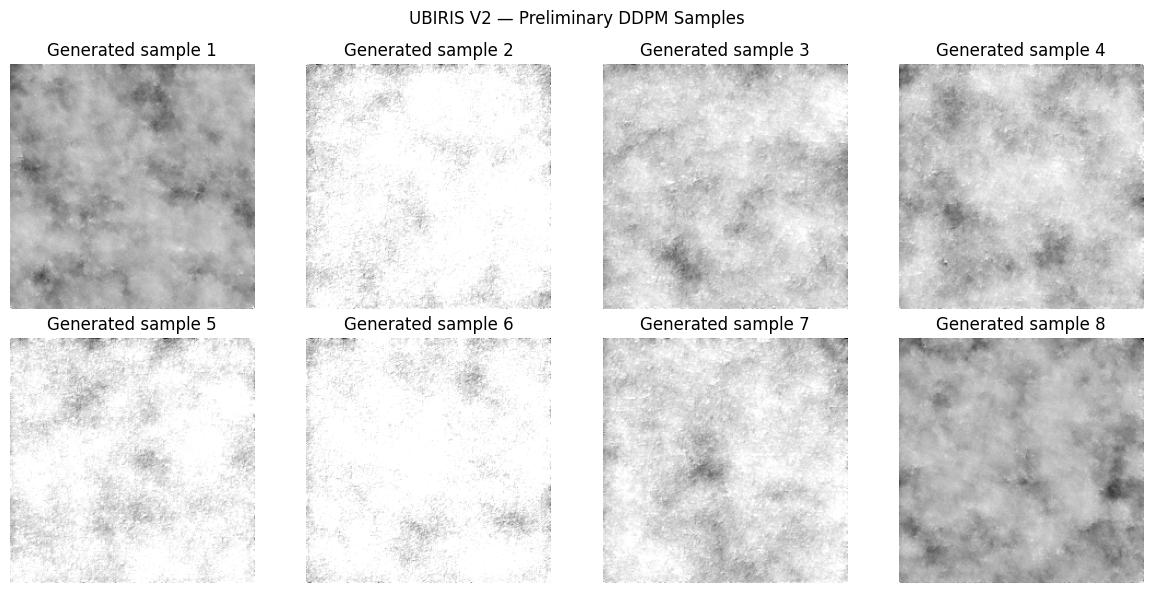

Checkpoint epoch: 2
Checkpoint training loss: 0.023884510317430743
Sample tensor shape: (8, 1, 224, 224)
Sample preview saved: /kaggle/working/ubiris_v2_project/notebook06_diffusion_training/UBIRIS_V2_ddpm_sample_preview.png


In [16]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path

OUT_DIR = Path("/kaggle/working/ubiris_v2_project/notebook06_diffusion_training")
CHECKPOINT_PATH = OUT_DIR / "UBIRIS_V2_ddpm_checkpoint.pth"
SAMPLE_PATH = OUT_DIR / "UBIRIS_V2_ddpm_sample_preview.png"

assert CHECKPOINT_PATH.is_file(), "Training checkpoint not found."

# Use the final trained model already in memory.
checkpoint = torch.load(
    CHECKPOINT_PATH, map_location=device, weights_only=False
)

state = checkpoint["model_state_dict"]
if isinstance(model, torch.nn.DataParallel):
    model.module.load_state_dict(state)
else:
    model.load_state_dict(state)

model.eval()

@torch.no_grad()
def sample_ddpm(model, num_samples=8):
    x = torch.randn(
        num_samples, 1, 224, 224, device=device
    )

    for t in reversed(range(TIMESTEPS)):
        timesteps = torch.full(
            (num_samples,), t, device=device, dtype=torch.long
        )

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            predicted_noise = model(x, timesteps).float()

        beta_t = betas[t]
        alpha_t = alphas[t]
        alpha_bar_t = alphas_cumprod[t]

        # DDPM reverse-process mean.
        x = (
            x - (beta_t / torch.sqrt(1.0 - alpha_bar_t))
            * predicted_noise
        ) / torch.sqrt(alpha_t)

        if t > 0:
            noise = torch.randn_like(x)
            alpha_bar_prev = alphas_cumprod[t - 1]
            posterior_variance = (
                beta_t * (1.0 - alpha_bar_prev)
                / (1.0 - alpha_bar_t)
            )
            x = x + torch.sqrt(posterior_variance) * noise

    return x.clamp(-1, 1)

samples = sample_ddpm(model, num_samples=8)
samples = (samples.cpu() + 1) / 2

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Generated sample {i + 1}")
    ax.axis("off")

fig.suptitle("UBIRIS V2 — Preliminary DDPM Samples")
fig.tight_layout()
fig.savefig(SAMPLE_PATH, dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Checkpoint epoch:", checkpoint["epoch"])
print("Checkpoint training loss:", checkpoint["mean_training_loss"])
print("Sample tensor shape:", tuple(samples.shape))
print("Sample preview saved:", SAMPLE_PATH)


In [17]:

from pathlib import Path
import csv
import time
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm

OUT_DIR = Path("/kaggle/working/ubiris_v2_project/notebook06_diffusion_training")
CHECKPOINT_PATH = OUT_DIR / "UBIRIS_V2_ddpm_checkpoint.pth"
HISTORY_PATH = OUT_DIR / "UBIRIS_V2_ddpm_training_history.csv"

assert CHECKPOINT_PATH.is_file(), "Existing diffusion checkpoint is missing."

checkpoint = torch.load(
    CHECKPOINT_PATH, map_location=device, weights_only=False
)

# Restore model and optimizer from the two-epoch pilot.
state = checkpoint["model_state_dict"]
if isinstance(model, torch.nn.DataParallel):
    model.module.load_state_dict(state)
else:
    model.load_state_dict(state)

optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

# Load previous history so results remain continuous.
if HISTORY_PATH.is_file():
    with open(HISTORY_PATH, newline="") as f:
        history = list(csv.DictReader(f))
else:
    history = []

START_EPOCH = int(checkpoint["epoch"]) + 1
END_EPOCH = START_EPOCH + 4  # Five additional epochs
scaler = torch.amp.GradScaler(
    "cuda", enabled=(device.type == "cuda")
)

print(f"Resuming from epoch {checkpoint['epoch']}")
print(f"Training epochs {START_EPOCH} through {END_EPOCH - 1}")

for epoch in range(START_EPOCH, END_EPOCH):
    model.train()
    total_loss = 0.0
    batches_seen = 0
    start = time.time()

    progress = tqdm(loader, desc=f"Epoch {epoch}/6")

    for images in progress:
        images = images.to(device, non_blocking=True)
        batch_size = images.shape[0]

        timesteps = torch.randint(
            0, TIMESTEPS, (batch_size,), device=device
        )
        noisy_images, true_noise = q_sample(images, timesteps)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            predicted_noise = model(noisy_images, timesteps)
            loss = F.mse_loss(
                predicted_noise.float(), true_noise.float()
            )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss at epoch {epoch}: {loss.item()}"
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )
        if not torch.isfinite(grad_norm):
            raise RuntimeError(f"Non-finite gradient at epoch {epoch}")

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        batches_seen += 1
        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            avg=f"{total_loss / batches_seen:.4f}"
        )

    mean_loss = total_loss / batches_seen
    epoch_seconds = time.time() - start

    record = {
        "epoch": epoch,
        "mean_training_loss": mean_loss,
        "batches": batches_seen,
        "epoch_seconds": round(epoch_seconds, 2),
        "learning_rate": optimizer.param_groups[0]["lr"]
    }
    history.append(record)

    with open(HISTORY_PATH, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=record.keys())
        writer.writeheader()
        writer.writerows(history)

    saved_state = (
        model.module.state_dict()
        if isinstance(model, torch.nn.DataParallel)
        else model.state_dict()
    )

    torch.save({
        "epoch": epoch,
        "model_state_dict": saved_state,
        "optimizer_state_dict": optimizer.state_dict(),
        "mean_training_loss": mean_loss,
        "timesteps": TIMESTEPS,
        "model_base_channels": 32
    }, CHECKPOINT_PATH)

    print(
        f"Epoch {epoch}: loss={mean_loss:.6f}, "
        f"time={epoch_seconds / 60:.2f} min"
    )

print("\nFINAL IMPROVEMENT RUN COMPLETE")
print("Checkpoint:", CHECKPOINT_PATH)
print("History:", HISTORY_PATH)
print("Latest epoch:", epoch)


Resuming from epoch 2
Training epochs 3 through 6


Epoch 3/6:   0%|          | 0/265 [00:00<?, ?it/s]

Epoch 3: loss=0.021047, time=0.60 min


Epoch 4/6:   0%|          | 0/265 [00:00<?, ?it/s]

Epoch 4: loss=0.019589, time=0.59 min


Epoch 5/6:   0%|          | 0/265 [00:00<?, ?it/s]

Epoch 5: loss=0.016509, time=0.60 min


Epoch 6/6:   0%|          | 0/265 [00:00<?, ?it/s]

Epoch 6: loss=0.016369, time=0.59 min

FINAL IMPROVEMENT RUN COMPLETE
Checkpoint: /kaggle/working/ubiris_v2_project/notebook06_diffusion_training/UBIRIS_V2_ddpm_checkpoint.pth
History: /kaggle/working/ubiris_v2_project/notebook06_diffusion_training/UBIRIS_V2_ddpm_training_history.csv
Latest epoch: 6


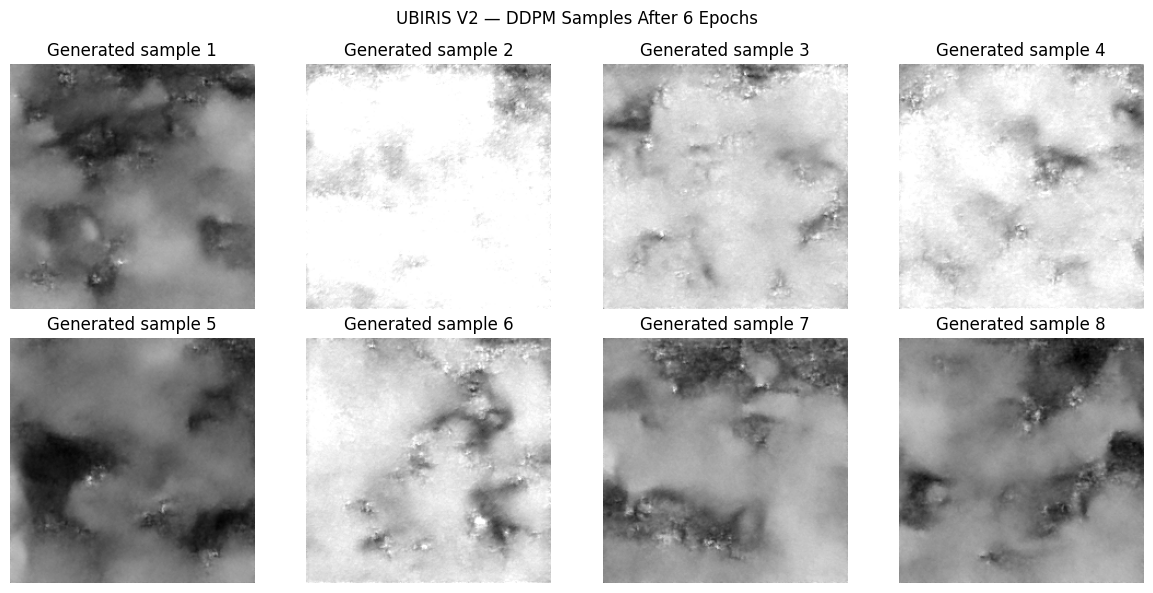

Checkpoint epoch: 6
Training loss: 0.016368905497047136
Sample shape: (8, 1, 224, 224)
Preview saved: /kaggle/working/ubiris_v2_project/notebook06_diffusion_training/UBIRIS_V2_ddpm_sample_preview.png


In [18]:

# Regenerate final preview using the latest epoch-6 checkpoint.
checkpoint = torch.load(
    CHECKPOINT_PATH, map_location=device, weights_only=False
)

state = checkpoint["model_state_dict"]
if isinstance(model, torch.nn.DataParallel):
    model.module.load_state_dict(state)
else:
    model.load_state_dict(state)

model.eval()

samples = sample_ddpm(model, num_samples=8)
samples = (samples.cpu() + 1) / 2

import matplotlib.pyplot as plt

SAMPLE_PATH = OUT_DIR / "UBIRIS_V2_ddpm_sample_preview.png"

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Generated sample {i + 1}")
    ax.axis("off")

fig.suptitle("UBIRIS V2 — DDPM Samples After 6 Epochs")
fig.tight_layout()
fig.savefig(SAMPLE_PATH, dpi=140, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Checkpoint epoch:", checkpoint["epoch"])
print("Training loss:", checkpoint["mean_training_loss"])
print("Sample shape:", tuple(samples.shape))
print("Preview saved:", SAMPLE_PATH)


# Conclusion — Diffusion Model Training on UBIRIS V2

A denoising diffusion probabilistic model (DDPM) was implemented and trained on the UBIRIS V2 ocular image dataset using a compact U-Net architecture. The preprocessed dataset contained 5,799 images, of which 4,243 were assigned to the training split. Images were converted to grayscale and resized to 224 × 224 pixels.

The model was trained for six epochs using a linear noise schedule with 1,000 diffusion timesteps, AdamW optimization, a learning rate of 0.0001, and mixed-precision computation. Training utilized the available Kaggle GPU environment.

The mean training loss decreased from 0.071654 in epoch 1 to 0.016369 in epoch 6, indicating improvement in the model's noise-prediction training objective. Eight synthetic samples were generated using the reverse diffusion process for preliminary visual inspection.

However, the generated samples continued to exhibit cloudy textures and intensity variations rather than clearly recognizable ocular structures. Therefore, the decrease in training loss did not translate into visibly satisfactory synthetic eye images within this experiment.

**Limitations:** The model was trained for a limited number of epochs, and no systematic hyperparameter search or quantitative evaluation of synthetic-image quality was conducted. The experiment did not establish that the generated samples preserve identity, improve biometric recognition, or provide privacy guarantees.

**Conclusion:** This experiment established a working DDPM training and sampling pipeline for UBIRIS V2, but the current configuration did not produce visually convincing synthetic ocular images. The checkpoint, training history, and sample preview are retained for reproducibility and future comparison with GAN-based augmentation and subsequent recognition experiments.

In [19]:

from pathlib import Path
import json
import zipfile
import pandas as pd
from IPython.display import display, FileLink

PROJECT = Path("/kaggle/working/ubiris_v2_project")
OUT_DIR = PROJECT / "notebook06_diffusion_training"
ZIP_PATH = Path("/kaggle/working/UBIRIS_V2_Notebook06_Results.zip")

CHECKPOINT_PATH = OUT_DIR / "UBIRIS_V2_ddpm_checkpoint.pth"
HISTORY_PATH = OUT_DIR / "UBIRIS_V2_ddpm_training_history.csv"
SAMPLE_PATH = OUT_DIR / "UBIRIS_V2_ddpm_sample_preview.png"

for path in [CHECKPOINT_PATH, HISTORY_PATH, SAMPLE_PATH]:
    assert path.is_file(), f"Missing required artifact: {path}"

history = pd.read_csv(HISTORY_PATH)
print("TRAINING HISTORY")
print(history.to_string(index=False))

print("\nFINAL CHECKS")
print("Checkpoint:", CHECKPOINT_PATH.stat().st_size, "bytes")
print("History rows:", len(history))
print("Sample preview:", SAMPLE_PATH.stat().st_size, "bytes")

# Keep the full Notebook 06 output directory in one ZIP.
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH, "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1,
    allowZip64=True
) as zf:
    for path in OUT_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, path.relative_to(PROJECT))

print(f"\nZIP created: {ZIP_PATH}")
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
display(FileLink(str(ZIP_PATH), result_html_prefix="Download Notebook 06 results: "))


TRAINING HISTORY
 epoch  mean_training_loss  batches  epoch_seconds  learning_rate
     1            0.071654      265      35.306183         0.0001
     2            0.023885      265      34.689280         0.0001
     3            0.021047      265      36.060000         0.0001
     4            0.019589      265      35.430000         0.0001
     5            0.016509      265      35.860000         0.0001
     6            0.016369      265      35.700000         0.0001

FINAL CHECKS
Checkpoint: 15533419 bytes
History rows: 6
Sample preview: 647018 bytes

ZIP created: /kaggle/working/UBIRIS_V2_Notebook06_Results.zip
ZIP size: 14.25 MB


/kaggle/working/UBIRIS_V2_Notebook06_Results.zip